In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
DATASET_PATH = r"C:\Users\admin\Downloads\PlantVillage"

print(os.listdir(DATASET_PATH))

['cnn_model.keras', 'mobilenetv2_model.keras', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'PlantVillage', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [3]:
classes = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Number of classes:", len(classes))

for i, cls in enumerate(classes):
    print(i, cls)

Number of classes: 16
0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 PlantVillage
3 Potato___Early_blight
4 Potato___Late_blight
5 Potato___healthy
6 Tomato_Bacterial_spot
7 Tomato_Early_blight
8 Tomato_Late_blight
9 Tomato_Leaf_Mold
10 Tomato_Septoria_leaf_spot
11 Tomato_Spider_mites_Two_spotted_spider_mite
12 Tomato__Target_Spot
13 Tomato__Tomato_YellowLeaf__Curl_Virus
14 Tomato__Tomato_mosaic_virus
15 Tomato_healthy


In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 41276 files belonging to 16 classes.
Using 33021 files for training.
Found 41276 files belonging to 16 classes.
Using 8255 files for validation.


In [5]:
class_names = train_ds.class_names

print(class_names)
print("Number of classes:", len(class_names))

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'PlantVillage', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Number of classes: 16


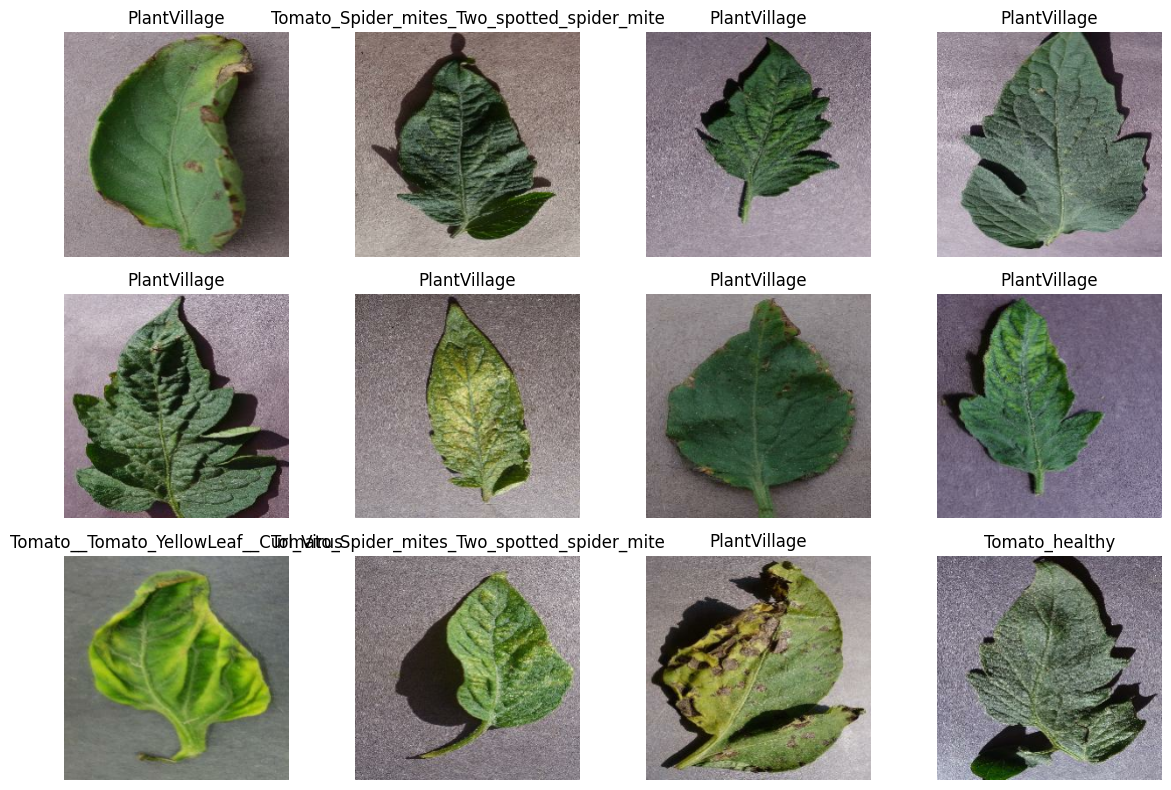

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

#### Model 1 — Custom CNN

In [9]:
cnn_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │           2,064 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,171,024 (42.61 MB)

 Trainable params: 11,171,024 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
EPOCHS = 2

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/2
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 1280s 1s/step - accuracy: 0.4907 - loss: 1.7322 - val_accuracy: 0.5037 - val_loss: 1.2858
Epoch 2/2
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 1253s 1s/step - accuracy: 0.4864 - loss: 1.4027 - val_accuracy: 0.4986 - val_loss: 1.1948


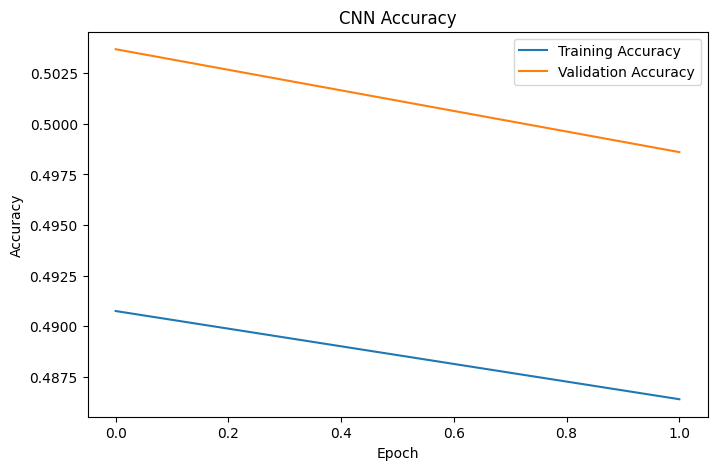

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()

plt.show()

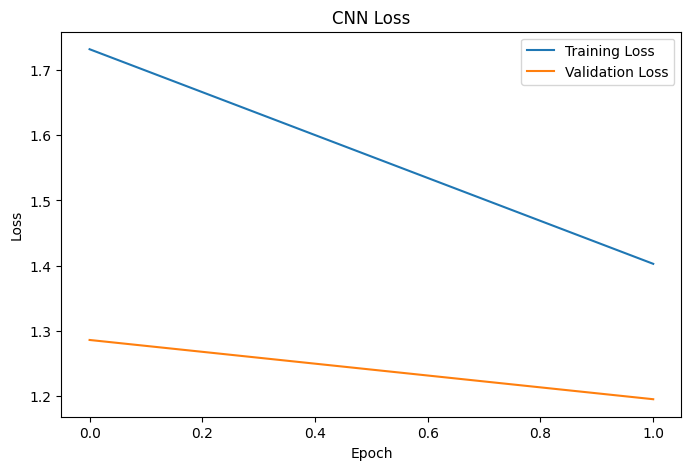

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()

plt.show()

In [14]:
os.makedirs(
    r"C:\Users\admin\Downloads\PlantVillage",
    exist_ok=True
)

cnn_model.save(
    r"C:\Users\admin\Downloads\PlantVillage\cnn_model.keras"
)


#### Model 2: MobileNetV2

In [15]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [16]:
mobilenet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(
        1./127.5,
        offset=-1
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.4),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

mobilenet_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │           2,064 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,424,016 (9.25 MB)

 Trainable params: 166,032 (648.56 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2
)

Epoch 1/2
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 1280s 1s/step - accuracy: 0.4799 - loss: 1.6049 - val_accuracy: 0.4933 - val_loss: 1.2150
Epoch 2/2
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 1130s 1s/step - accuracy: 0.4870 - loss: 1.2639 - val_accuracy: 0.4893 - val_loss: 1.0930


In [19]:
mobilenet_model.save(
    r"C:\Users\admin\Downloads\PlantVillage\mobilenetv2_model.keras"
)

#### Model 3 — ResNet50

In [20]:
from tensorflow.keras.applications import ResNet50

resnet_base = ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

resnet_base.trainable = False

In [21]:
resnet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(
        1./127.5,
        offset=-1
    ),

    resnet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),

    layers.Dropout(0.5),

    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

resnet_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_2 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 16)                  │           4,112 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,116,368 (92.00 MB)

 Trainable params: 528,656 (2.02 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [22]:

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2
)

Epoch 1/2
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 2594s 3s/step - accuracy: 0.4927 - loss: 1.9810 - val_accuracy: 0.5028 - val_loss: 1.7845
Epoch 2/2
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 2671s 3s/step - accuracy: 0.4976 - loss: 1.8391 - val_accuracy: 0.5004 - val_loss: 1.7099


In [24]:
resnet_model.save(
    r"C:\Users\admin\Downloads\PlantVillage\resnet50_model.keras"
)

In [25]:
cnn_loss, cnn_acc = cnn_model.evaluate(val_ds)

mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(val_ds)

resnet_loss, resnet_acc = resnet_model.evaluate(val_ds)

print("CNN Accuracy:", cnn_acc)
print("MobileNetV2 Accuracy:", mobilenet_acc)
print("ResNet50 Accuracy:", resnet_acc)

258/258 ━━━━━━━━━━━━━━━━━━━━ 100s 384ms/step - accuracy: 0.4986 - loss: 1.1948
258/258 ━━━━━━━━━━━━━━━━━━━━ 217s 841ms/step - accuracy: 0.4893 - loss: 1.0930
258/258 ━━━━━━━━━━━━━━━━━━━━ 843s 3s/step - accuracy: 0.5004 - loss: 1.7099
CNN Accuracy: 0.4986068904399872
MobileNetV2 Accuracy: 0.48927921056747437
ResNet50 Accuracy: 0.5004239678382874


In [26]:
comparison = pd.DataFrame({
    "Model": [
        "CNN",
        "MobileNetV2",
        "ResNet50"
    ],
    "Accuracy": [
        cnn_acc,
        mobilenet_acc,
        resnet_acc
    ]
})

comparison

,Model,Accuracy
0,CNN,0.498607
1,MobileNetV2,0.489279
2,ResNet50,0.500424


In [27]:
scores = {
    "CNN": cnn_acc,
    "MobileNetV2": mobilenet_acc,
    "ResNet50": resnet_acc
}

best_model_name = max(
    scores,
    key=scores.get
)

print("Best Model:", best_model_name)
print("Accuracy:", scores[best_model_name])

Best Model: ResNet50
Accuracy: 0.5004239678382874


In [28]:
from tensorflow.keras.utils import load_img, img_to_array

MODEL_PATH = r"C:\Users\admin\Downloads\PlantVillage\resnet50_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)

In [29]:
def predict_disease(image_path):

    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = img_to_array(img)

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    img_array = img_array / 127.5 - 1

    predictions = model.predict(img_array)

    predicted_index = np.argmax(predictions[0])

    disease = class_names[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    return disease, confidence

In [31]:
image_path = "img1.png"

disease, confidence = predict_disease(image_path)

print("Predicted Disease:", disease)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted Disease: PlantVillage
Confidence: 49.31 %


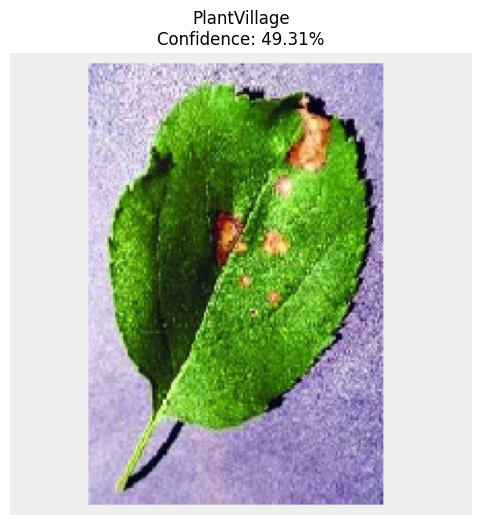

In [32]:
img = load_img(
    image_path,
    target_size=(224, 224)
)

plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"{disease}\nConfidence: {confidence:.2f}%"
)

plt.axis("off")
plt.show()

In [33]:
recommendations = {

    "Tomato___Early_blight": {
        "treatment": "Remove severely affected leaves and use an appropriate fungicide according to the product label.",
        "prevention": "Avoid overhead irrigation and maintain good spacing between plants."
    },

    "Tomato___Late_blight": {
        "treatment": "Remove affected plant material and follow locally recommended late-blight management practices.",
        "prevention": "Keep foliage dry when possible and provide good air circulation."
    },

    "Tomato___healthy": {
        "treatment": "No disease treatment is indicated by this classification.",
        "prevention": "Continue monitoring the plant and maintain proper irrigation and nutrition."
    },

    "Potato___Early_blight": {
        "treatment": "Remove heavily affected foliage and follow recommended disease-management practices.",
        "prevention": "Maintain plant spacing and avoid prolonged leaf wetness."
    },

    "Potato___Late_blight": {
        "treatment": "Remove affected material and follow locally recommended late-blight control practices.",
        "prevention": "Monitor plants regularly and reduce prolonged moisture on leaves."
    },

    "Potato___healthy": {
        "treatment": "No disease treatment is indicated by this classification.",
        "prevention": "Continue regular crop monitoring."
    }
}

In [34]:
if disease in recommendations:

    print("Disease:")
    print(disease)

    print("\nConfidence:")
    print(f"{confidence:.2f}%")

    print("\nTreatment:")
    print(recommendations[disease]["treatment"])

    print("\nPrevention:")
    print(recommendations[disease]["prevention"])

else:

    print("Recommendation not available for this disease.")

Recommendation not available for this disease.


In [41]:
import os

print(os.getcwd())

C:\Users\admin\Projects\Plant Disease Prediction And Recommendation
